# Capstone 09: Customer purchase pipeline
An annotated walkthrough of the included pipeline, database and dashboard. Run from the project root or notebooks folder. The saved outputs come from actual Python execution.

In [1]:
from pathlib import Path
import sys, csv, json, sqlite3
ROOT = Path.cwd()
if not (ROOT / 'scripts').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
print('Project:', ROOT.name)

Project: capstone09-model-building


## 1. Read the six-field raw dataset
These are synthetic profiles and simulated purchases, not real transactions.

In [2]:
with (ROOT/'data/raw/dataset.csv').open(newline='',encoding='utf-8') as f:
    rows=list(csv.DictReader(f))
print('Raw rows:',len(rows))
for row in rows[:3]: print(row)

Raw rows: 10000
{'CustomerID': '1', 'Name': 'Josephine Nelson', 'Age': '69', 'PurchaseAmount': '210.22', 'Country': 'Australia', 'Date': '2025-09-13'}
{'CustomerID': '2', 'Name': 'Lily Bélanger', 'Age': '44', 'PurchaseAmount': '256.59', 'Country': 'Canada', 'Date': '2025-01-04'}
{'CustomerID': '3', 'Name': 'June Austin', 'Age': '70', 'PurchaseAmount': '166.17', 'Country': 'Australia', 'Date': '2025-04-21'}


## 2. Run cleaning, enrichment, validation and loading
Read scripts/pipeline.py for the full implementation. Any invalid row blocks publication.

In [3]:
from pipeline import run
summary=run(ROOT)
print(json.dumps({k:v for k,v in summary.items() if not isinstance(v,list)},indent=2))

{
  "rows": 10000,
  "customers": 10000,
  "revenue_cents": 268199306,
  "revenue_cad": 2681993.06,
  "average_purchase_cad": 268.199306,
  "countries": 4,
  "min_date": "2025-01-01",
  "max_date": "2025-12-31"
}


## 3. Inspect the analytical model
Dimensions describe customers, countries and dates. The fact table stores one purchase per source row.

In [4]:
with sqlite3.connect(ROOT/'data/capstone.sqlite') as con:
    print(con.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name").fetchall())
    print('Foreign key issues:',con.execute('PRAGMA foreign_key_check').fetchall())
    print('Country totals (CAD):')
    for row in con.execute('SELECT country,COUNT(*),SUM(purchase_cents)/100.0 FROM analytics_purchases GROUP BY country ORDER BY SUM(purchase_cents) DESC'): print(row)

[('dim_country',), ('dim_customer',), ('dim_date',), ('fact_purchase',)]
Foreign key issues: []
Country totals (CAD):
('United States', 2516, 695220.29)
('United Kingdom', 2529, 692012.05)
('Canada', 2493, 668571.59)
('Australia', 2462, 626189.13)


## 4. Inspect validation and monitoring
The logs are evidence from actual runs. Scheduled hosting still needs activation and verification in GitHub.

In [5]:
print((ROOT/'logs/validation.json').read_text())
print((ROOT/'logs/last_run.json').read_text())

{
  "raw_rows": 10000,
  "accepted_rows": 10000,
  "rejected_rows": 0,
  "duplicates_removed": 0,
  "null_values": 0,
  "foreign_key_violations": 0,
  "source_target_rows_match": true,
  "source_target_cents_match": true,
  "raw_sha256": "3c2979474030366c7cbdfe1921451cf9ce03cfd791f9711602fc6c2c6cc6a370",
  "raw_unchanged": true
}
{
  "run_id": "c7dfb1ecc6e843f9baa0303e942d1887",
  "started_utc": "2026-10-28T14:47:14.285302+00:00",
  "status": "success",
  "rows": 10000,
  "revenue_cents": 268199306,
  "duration_seconds": 0.3838,
  "finished_utc": "2026-10-28T14:47:14.669067+00:00"
}


## 5. Visual results
Open dashboards/Customer_Purchases_Dashboard.xlsx for native Excel charts. The PNG below is a static alternative.

Dashboard: Customer_Purchases_Dashboard.xlsx


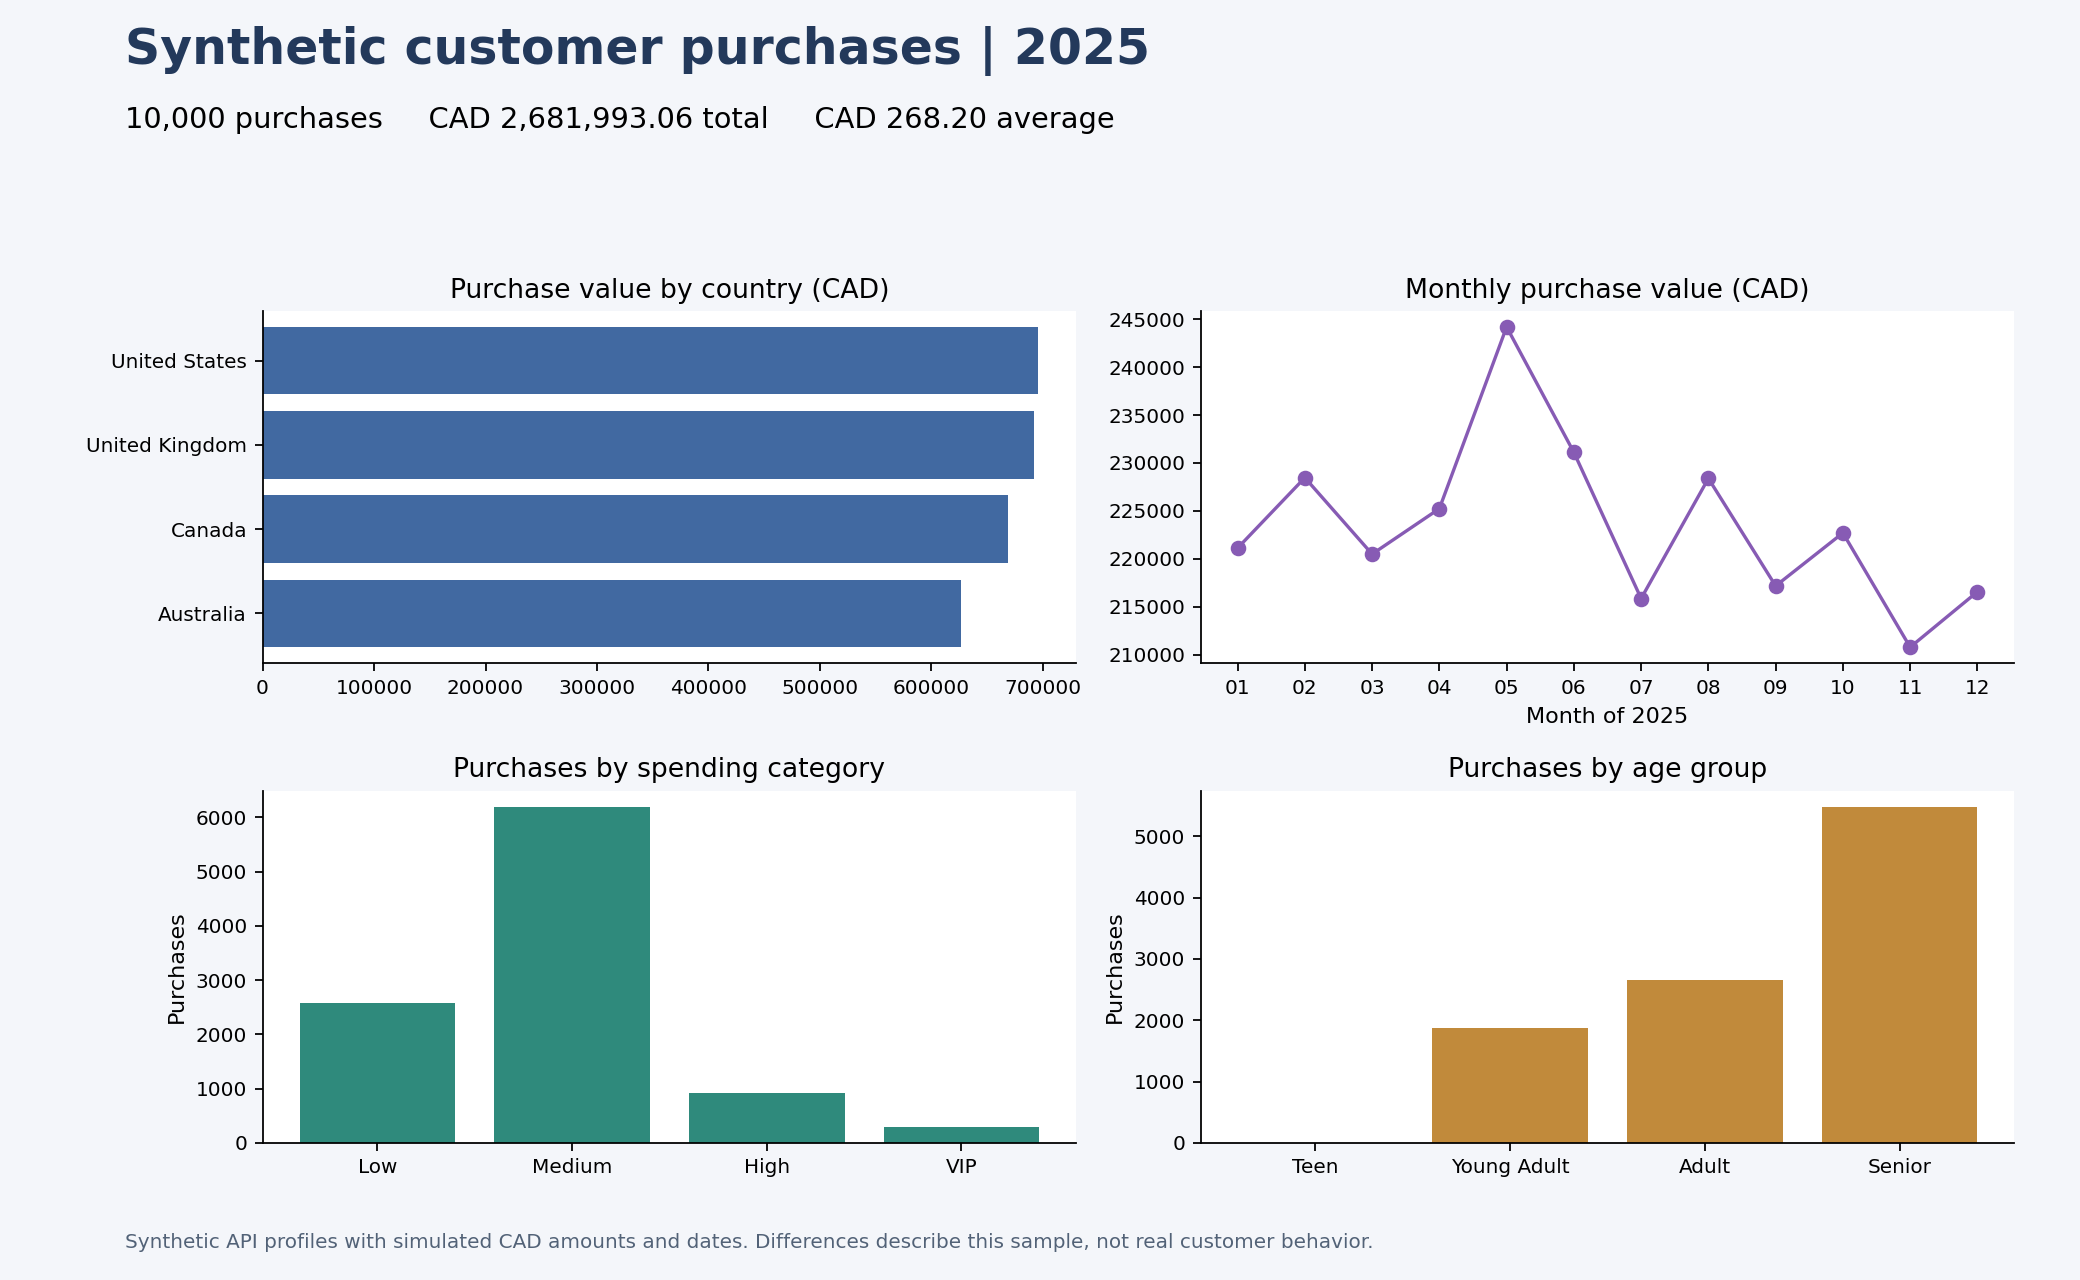

In [6]:
print('Dashboard:', (ROOT/'dashboards/Customer_Purchases_Dashboard.xlsx').name)

## Interpretation
The snapshot totals CAD 2,681,993.06 across 10,000 purchases, with a CAD 268.20 average. These descriptive results depend on the simulation. They do not establish real market trends. See README.md for source provenance, boundaries, reproducibility, tests and submission instructions.